# Bornholm BikeNodePlanner–OSM overlap

In [1]:
# Run once if your environment is missing packages:
#%pip install geopandas osmnx matplotlib pandas shapely pyogrio


In [2]:
#!pip install pyrosm pyarrow requests

## 1. Setup

In [3]:
from pathlib import Path
import lzma
import pickle

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import requests
import numpy as np

from pyrosm import OSM
import shapely
from shapely.affinity import translate
from shapely.geometry import Point
from IPython.display import display

working_dir = Path.cwd().resolve()
PROJECT_ROOT = working_dir.parent if working_dir.name == "osm_data_exploration" else working_dir

SAMPLE = "denmark"
osm_sample = "denmark"

DATA_PATH = PROJECT_ROOT / f"bikenwloops/data/processed/{SAMPLE}/network_preprocessed.xz"

# output folders
OSM_DIR = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}"

OSM_GRAPH_PATH = OSM_DIR / f"{SAMPLE}_bike_network.graphml"
PBF_PATH = OSM_DIR / "denmark-latest.osm.pbf"
OSM_EDGES_PATH = OSM_DIR / f"{SAMPLE}_bike_edges.parquet"

OUTPUT_DIR = OSM_DIR / "overlap_clean"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Output folder:", OUTPUT_DIR)

Project root: /Users/ellenebdrup/Documents/GitHub/bike_safety
Output folder: /Users/ellenebdrup/Documents/GitHub/bike_safety/osm_data_exploration/outputs/denmark/overlap_clean


#### Load the complete BikeNodePlanner study network

In [4]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Study network not found:\n{DATA_PATH}"
    )

with lzma.open(DATA_PATH, "rb") as file:
    study_graph = pickle.load(file)

print(study_graph.summary())

IGRAPH UNW- 7170 10814 -- 
+ attr: name (v), x (v), y (v), edge_id (e), geometry (e), has_attraction (e), has_facility (e), has_service (e), has_water (e), max_slope (e), node_end (e), node_start (e), poi_diversity (e), weight (e)


In [5]:
STUDY_CRS = "EPSG:25832"

# Nodes
study_nodes = gpd.GeoDataFrame(
    {
        "node_id": range(study_graph.vcount()),
        "name": study_graph.vs["name"],
        "x": study_graph.vs["x"],
        "y": study_graph.vs["y"],
    },
    geometry=gpd.points_from_xy(
        study_graph.vs["x"],
        study_graph.vs["y"],
    ),
    crs=STUDY_CRS,
)

# Edges
study_edges = gpd.GeoDataFrame(
    {
        attribute: study_graph.es[attribute]
        for attribute in study_graph.es.attribute_names()
    },
    geometry="geometry",
    crs=STUDY_CRS,
)

study_edges[["source", "target"]] = study_graph.get_edgelist()

print(f"Study nodes: {len(study_nodes):,}")
print(f"Study edges: {len(study_edges):,}")

AREA_NAMES = ["bornholm", "funen", "jutland", "lollandfalster", "longland", "zealand",]

membership = study_graph.connected_components().membership

study_nodes["area"] = [AREA_NAMES[component] for component in membership]
study_edges["area"] = [AREA_NAMES[membership[source]] for source in study_edges["source"]]

Study nodes: 7,170
Study edges: 10,814


In [ ]:
# Move Bornholm to correct place on map

bornholm_nodes = study_nodes["area"] == "bornholm"
bornholm_edges = study_edges["area"] == "bornholm"

study_nodes.loc[bornholm_nodes, "geometry"] = (
    study_nodes.loc[bornholm_nodes, "geometry"]
    .translate(xoff=220_000, yoff=-120_000)
)

study_edges.loc[bornholm_edges, "geometry"] = (
    study_edges.loc[bornholm_edges, "geometry"]
    .translate(xoff=220_000, yoff=-120_000)
)

# Update the coordinate columns too
study_nodes.loc[bornholm_nodes, "x"] += 220_000
study_nodes.loc[bornholm_nodes, "y"] -= 120_000

,edges,length_km
area,,
bornholm,89,375.7
funen,1240,2577.0
jutland,6502,18341.0
lollandfalster,638,1451.4
longland,88,232.7
zealand,2257,5237.5


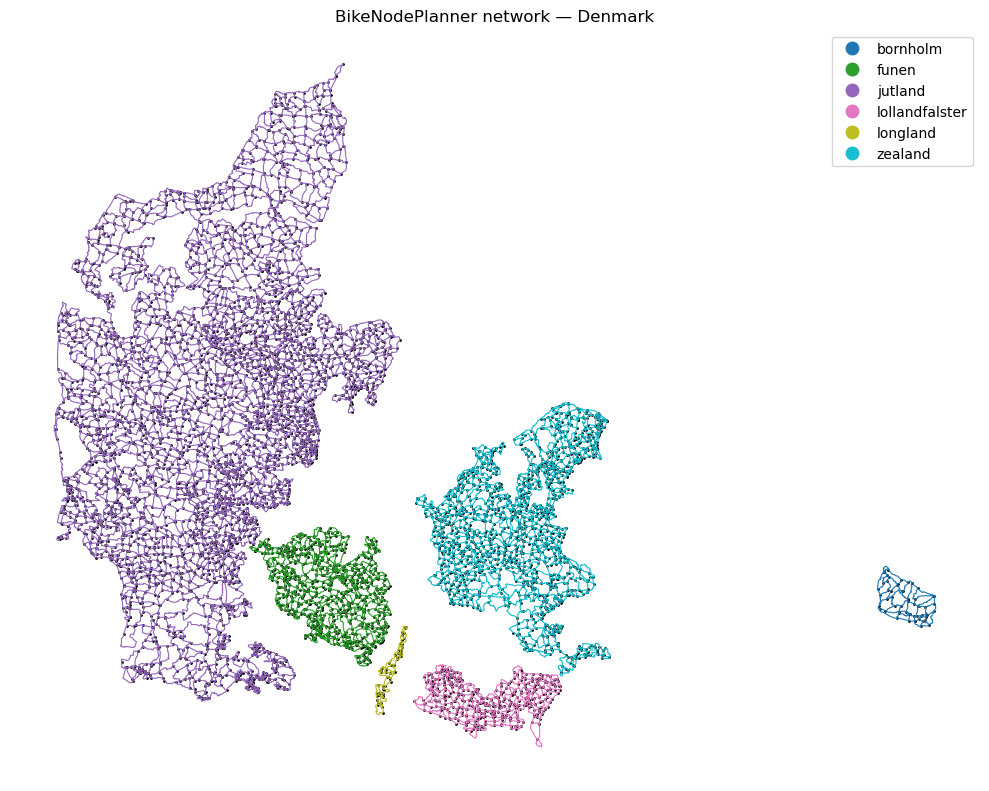

In [7]:
study_edges["study_length_m"] = study_edges.length

display(
    study_edges.groupby("area").agg(
        edges=("edge_id", "count"),
        length_km=("study_length_m", lambda x: x.sum() / 1000),
    ).round(1)
)

ax = study_edges.plot(column="area", figsize=(10, 15), linewidth=0.8, legend=True,)
study_nodes.plot(ax=ax, color="black", markersize=1,)
ax.set_title("BikeNodePlanner network — Denmark")
ax.set_axis_off()
plt.tight_layout()
plt.show()

#### Download the Denmark OSM extract

In [8]:
PBF_URL = "https://download.geofabrik.de/europe/denmark-latest.osm.pbf"

if not PBF_PATH.exists():
    print("Downloading Denmark OSM data...")
    print("This can take several minutes.")

    temporary_path = PBF_PATH.with_suffix(".download")

    with requests.get(PBF_URL, stream=True, timeout=120) as response:
        response.raise_for_status()

        total_bytes = int(response.headers.get("content-length", 0))
        downloaded_bytes = 0

        with temporary_path.open("wb") as file:
            for chunk in response.iter_content(chunk_size=8 * 1024 * 1024):
                if chunk:
                    file.write(chunk)
                    downloaded_bytes += len(chunk)

                    if total_bytes:
                        percentage = 100 * downloaded_bytes / total_bytes
                        print(
                            f"\rDownloaded: {percentage:5.1f}%",
                            end="",
                        )

    temporary_path.replace(PBF_PATH)
    print("\nDownload completed.")

else:
    print("Using existing Denmark OSM file.")

print("OSM file:", PBF_PATH)

Using existing Denmark OSM file.
OSM file: /Users/ellenebdrup/Documents/GitHub/bike_safety/osm_data_exploration/outputs/denmark/denmark-latest.osm.pbf


#### Extract and cache the OSM bicycle network

In [9]:
if OSM_EDGES_PATH.exists():
    print("Loading the cached OSM bicycle network...")
    osm_edges = gpd.read_parquet(OSM_EDGES_PATH)

else:
    print("Extracting bicycle-accessible OSM roads...")
    print("The first extraction may take several minutes.")

    osm_reader = OSM(str(PBF_PATH))
    osm_edges = osm_reader.get_network(network_type="cycling")

    osm_edges = osm_edges.loc[
        osm_edges.geometry.notna()
        & ~osm_edges.geometry.is_empty
    ].copy()

    # Convert multipart ways to individual line records
    osm_edges = osm_edges.explode(index_parts=False, ignore_index=True,)
    osm_edges = osm_edges.to_crs(STUDY_CRS)
    osm_edges.to_parquet(OSM_EDGES_PATH)

    print("Saved cached OSM bicycle network.")

print(f"OSM bicycle ways: {len(osm_edges):,}")
print("OSM CRS:", osm_edges.crs)

Loading the cached OSM bicycle network...
OSM bicycle ways: 6,717,277
OSM CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "ProjectedCRS", "name": "ETRS89 / UTM zone 32N", "base_crs": {"type": "GeographicCRS", "name": "ETRS89", "datum_ensemble": {"name": "European Terrestrial Reference System 1989 ensemble", "members": [{"name": "European Terrestrial Reference Frame 1989"}, {"name": "European Terrestrial Reference Frame 1990"}, {"name": "European Terrestrial Reference Frame 1991"}, {"name": "European Terrestrial Reference Frame 1992"}, {"name": "European Terrestrial Reference Frame 1993"}, {"name": "European Terrestrial Reference Frame 1994"}, {"name": "European Terrestrial Reference Frame 1996"}, {"name": "European Terrestrial Reference Frame 1997"}, {"name": "European Terrestrial Reference Frame 2000"}, {"name": "European Terrestrial Reference Frame 2005"}, {"name": "European Terrestrial Reference Frame 2014"}, {"name": "European Terrestrial Reference Fr